# 02 MCDM Matrix

Builds the hard-exclusion mask (a cell is **excluded** if it fails any physical, environmental, legal or logistics constraint) and the MCDM matrix of the surviving cells, the valid "alternatives".

In [ ]:
import re
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import binary_erosion

from gis_mcdm import alpha_tag, ask_choice, ask_number, load_config, normalized, write_matrix_info

cfg, P = load_config()  # config.toml: constraints, scenarios, criteria, run defaults
ALIGNED_DIR, MASKS_DIR, MATRICES_DIR, FIGURES_DIR = P.aligned, P.masks, P.matrices, P.figures
for folder in (MASKS_DIR, MATRICES_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Figures are drawn at their printed size (letter page, 6.5 in text width) with 9 pt Palatino.
# Saved as PNG (600 dpi): insert them in Word at 100 % so the text stays at 9 pt.
TEXT_WIDTH = 6.5
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Palatino Linotype", "Palatino", "Book Antiqua", "TeX Gyre Pagella", "DejaVu Serif"],
    "mathtext.fontset": "custom", "mathtext.rm": "serif",
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "figure.dpi": 200,  # sharper preview in the notebook
    "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
})


def save_figure(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png")

In [ ]:
# Run parameters (press Enter to keep the default from config.toml shown in brackets)
INTERACTIVE = cfg["run"]["interactive"]
RESOLUTION = ask_number("Which resolution (m)?", cfg["run"]["resolution"], INTERACTIVE)
RES_TAG = f"{RESOLUTION:g}m"
ANCHOR_PATH = P.study_area / f"anchor_grid_{RES_TAG}.tif"
if not ANCHOR_PATH.exists():
    raise FileNotFoundError(f"{ANCHOR_PATH.name} not found. Run 01_Data_Preprocessing at {RES_TAG} first.")


def gravity_alphas(name):
    """Alphas of the <name>_<alpha>_<RES_TAG>.tif layers created by 01."""
    pattern = re.compile(rf"^{re.escape(name)}_([\d.]+)_{re.escape(RES_TAG)}\.tif$")
    return {float(m.group(1)) for f in ALIGNED_DIR.glob(f"{name}_*.tif") if (m := pattern.match(f.name))}


# Gravity criteria share one alpha, asked only if 01 created at least one of them at this resolution
gravity_found = {c["layer"]: alphas for c in cfg["criteria"]
                 if cfg["layers"][c["layer"]]["kind"] == "gravity" and (alphas := gravity_alphas(c["layer"]))}
if gravity_found:
    alphas = sorted(set.intersection(*gravity_found.values()))
    ALPHA = ask_number(f"Which alpha for the gravity layers? (available: {', '.join(f'{a:g}' for a in alphas)})",
                       cfg["run"]["gravity_alpha"], INTERACTIVE, allowed=alphas)
else:
    ALPHA = None  # "NA" in the output names: run without gravity criteria
ALPHA_TAG = alpha_tag(ALPHA)


def layer_path(name):
    """Aligned layer <name>_<RES_TAG>.tif (gravity: <name>_<alpha>_<RES_TAG>.tif), or None if 01 did not create it."""
    if cfg["layers"][name]["kind"] == "gravity":
        path = ALIGNED_DIR / f"{name}_{ALPHA_TAG}_{RES_TAG}.tif" if ALPHA is not None else None
    else:
        path = ALIGNED_DIR / f"{name}_{RES_TAG}.tif"
    return path if path is not None and path.exists() else None

## 1. Exclusion mask

In [ ]:
# Constraints and scenario thresholds are defined in config.toml ([[constraints]] and [scenarios])
SCENARIO = ask_choice("Which scenario?", list(cfg["scenarios"]), cfg["run"]["scenario"], INTERACTIVE)
params = cfg["scenarios"][SCENARIO]

RUN_TAG = f"{SCENARIO}_{ALPHA_TAG}_{RES_TAG}"
OUTPUT_MASK_PATH = MASKS_DIR / f"Master_Exclusion_Mask_{RUN_TAG}.tif"
OUTPUT_CSV_PATH = MATRICES_DIR / f"MCDM_Matrix_{RUN_TAG}.csv"
print(f"Run: {RUN_TAG}")

In [ ]:
def threshold(value):
    """A number, or the value of that parameter in the chosen scenario."""
    return params[value] if isinstance(value, str) else value


def meets(rule, a, nodata):
    """True where a cell meets the constraint; NoData cells never do."""
    ok = np.ones(a.shape, dtype=bool) if nodata is None else a != nodata
    if np.issubdtype(a.dtype, np.floating):
        ok &= ~np.isnan(a)
    if "min" in rule:
        ok &= a >= threshold(rule["min"])
    if "max" in rule:
        ok &= a <= threshold(rule["max"])
    if "exclude" in rule:
        ok &= ~np.isin(a, rule["exclude"])
    if (buffer_pixels := int(rule.get("buffer_m", 0) / RESOLUTION)) > 0:
        ok = binary_erosion(ok, iterations=buffer_pixels)  # the excluded area grows by buffer_m
    return ok


with rasterio.open(ANCHOR_PATH) as src:
    study_area, profile = src.read(1) == 1, src.profile  # anchor grid: 1 = inside the study area

# A cell is viable only if it meets every constraint whose layer exists
viable = study_area.copy()
skipped = []
for rule in cfg["constraints"]:
    if (path := layer_path(rule["layer"])) is None:
        skipped.append(rule["layer"])
        continue
    with rasterio.open(path) as src:
        viable &= meets(rule, src.read(1), src.nodata)
if skipped:
    print(f"Constraints skipped (layer not found): {', '.join(skipped)}")

# 1 = viable, 0 = excluded, 255 = outside the study area (NoData)
profile.update(dtype="uint8", nodata=255, compress="deflate")
with rasterio.open(OUTPUT_MASK_PATH, "w", **profile) as dst:
    dst.write(np.where(study_area, viable, 255).astype(np.uint8), 1)

n_viable, n_area = np.count_nonzero(viable), np.count_nonzero(study_area)
print(f"{OUTPUT_MASK_PATH.name}: {n_viable:,} of {n_area:,} cells viable ({100 * n_viable / n_area:.2f}% of the study area)")

## 2. MCDM matrix

In [ ]:
# Criteria from config.toml; a criterion whose layer 01 did not create is skipped
CRITERIA, skipped = [], []
for crit in cfg["criteria"]:
    if (path := layer_path(crit["layer"])) is None:
        skipped.append(crit["layer"])
        continue
    CRITERIA.append({"column": crit["layer"], "file": path.name, "type": crit["type"],
                     "label": crit.get("label", crit["layer"]), "transform": crit.get("transform", "none"),
                     "scaled": crit.get("scaled", False)})
if skipped:
    print(f"Criteria skipped (layer not found): {', '.join(skipped)}")
if len(CRITERIA) < 2:
    raise ValueError(f"Only {len(CRITERIA)} criterion layer found in {ALIGNED_DIR}; the MCDM needs at least two.")
CRIT = {c["column"]: c for c in CRITERIA}
LABELS = {col: c["label"] for col, c in CRIT.items()}
crit_cols = list(CRIT)

rows, cols = np.nonzero(viable)
t = profile["transform"]
data = {"Row_Idx": rows, "Col_Idx": cols,
        "X_Coord": t.c + (cols + 0.5) * t.a, "Y_Coord": t.f + (rows + 0.5) * t.e}  # cell centres
for c in CRITERIA:
    with rasterio.open(ALIGNED_DIR / c["file"]) as src:
        values = src.read(1)[viable]
        data[c["column"]] = values if src.nodata is None else np.where(values == src.nodata, np.nan, values)
mcdm_df = pd.DataFrame(data)

n_cells = len(mcdm_df)
mcdm_df = mcdm_df.dropna()
if len(mcdm_df) < n_cells:
    print(f"Warning: {n_cells - len(mcdm_df):,} cells dropped for NoData in some criterion")

mcdm_df.to_csv(OUTPUT_CSV_PATH, index=False)
write_matrix_info(OUTPUT_CSV_PATH, CRITERIA)  # criteria, types and scaling, read by 03 and 04
print(f"{OUTPUT_CSV_PATH.name}: {len(mcdm_df):,} cells x {len(CRITERIA)} criteria")

## 3. Criteria distributions and correlation

In [ ]:
# 0-1 scale as used for the weights in 03: transform (e.g. log), costs inverted, benefits min-max
norm_df = pd.DataFrame({col: normalized(mcdm_df[col], CRIT[col]) for col in crit_cols}, index=mcdm_df.index)

In [ ]:
n_rows = -(-len(crit_cols) // 3)
fig, axes = plt.subplots(n_rows, 3, figsize=(TEXT_WIDTH, 1.4 * n_rows), sharex=True, squeeze=False,
                         layout="constrained")  # squeeze=False: axes stays 2-D with a single row

for ax, col in zip(axes.flat, crit_cols):
    values = norm_df[col]
    counts, edges = np.histogram(values, bins=40, range=(0, 1))
    pct = 100 * counts / len(values)
    ax.bar(edges[:-1], pct, width=np.diff(edges), align="edge",
           color="lightgray", edgecolor="black", linewidth=0.3)
    ax.axvline(values.mean(), color="red", linestyle="--", linewidth=0.9)
    ax.set_ylim(0, pct.max() * 1.6)  # headroom so the statistics never cover the bars
    x = 0.03 if values.mean() > 0.5 else 0.97  # statistics on the emptier side
    ax.text(x, 0.95, f"Skew {values.skew():.2f}\nKurt {values.kurt():.2f}", transform=ax.transAxes,
            fontsize=8, ha="left" if x < 0.5 else "right", va="top")
    ax.set_title(LABELS[col])
    ax.set_xlim(0, 1)
    ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.7)

for ax in axes.flat[len(crit_cols):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("Cells (%)")
for ax in axes[-1]:
    ax.set_xlabel("Normalized value")

save_figure(fig, f"Normalized_Criteria_Histograms_{RUN_TAG}")
plt.show()

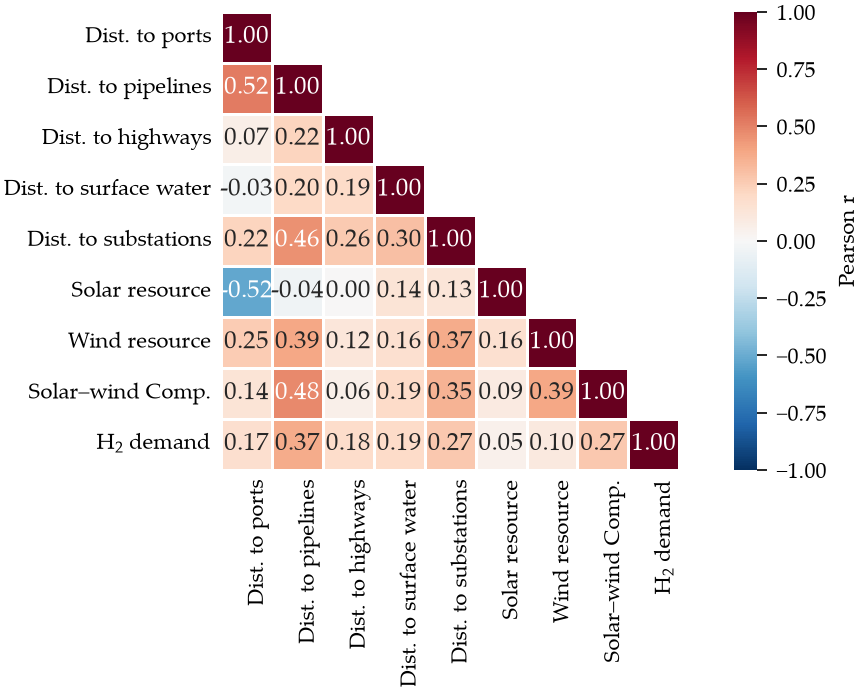

In [118]:
corr = norm_df.rename(columns=LABELS).corr().round(2) + 0.0  # + 0.0 turns -0.00 into 0.00

fig, ax = plt.subplots(figsize=(TEXT_WIDTH, 3.5), layout="constrained")
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap="RdBu_r", vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"fontsize": 9}, square=True, linewidths=0.5,
            cbar_kws={"label": "Pearson r", "shrink": 1.0}, ax=ax)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha="right", rotation_mode="anchor")
ax.tick_params(length=0)

save_figure(fig, f"Criteria_Correlation_{RUN_TAG}")
plt.show()